# Tarea 1 – Parte 1: Recolección, limpieza y EDA

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

| Parámetro | Valor |
|---|---|
| Opción elegida | **A – La República** |
| Fecha de descarga | **17 de octubre de 2026** (también queda guardada en `datos/raw/fecha_descarga.txt`) |
| URL base | https://larepublica.pe |
| Canales RSS oficiales | `/rss/politica.xml`, `/rss/economia.xml`, `/rss/deportes.xml`, `/rss/ciencia.xml`, `/rss/home.xml` |
| Sitemaps de noticias | `/sitemap/{seccion}.xml`, `/sitemap/web/{seccion}.xml`, `/sitemap/noticias.xml` |
| Categorías finales | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |

### Estrategia de extracción
1. **robots.txt revisado**: permite `/rss/*`, `/sitemap/*` y las páginas de noticia; prohíbe la paginación de secciones (`/*/pag/*`, `/*/*/page/*`), búsquedas, `/tag/*` y `/archivo/*`.
2. **Bloqueo documentado**: el botón *“Ver más noticias”* de cada sección usa `/api/search/articles`, que responde **403 Forbidden** a clientes que no son navegador. **No se intenta evadir** ese bloqueo.
3. **Solución**: se visitan las páginas de noticia (permitidas por robots.txt) obtenidas del RSS y se siguen los enlaces a *otras noticias de la misma sección* que cada artículo enlaza (“más noticias”, relacionadas). De cada página se lee `og:title`, `og:description` (bajada) y `mrf:sections`.

In [1]:
import json, re, time, random
from datetime import datetime
from pathlib import Path
from collections import Counter, deque

import requests
import pandas as pd
from bs4 import BeautifulSoup
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_colwidth", 120)

BASE = "https://larepublica.pe"
MEDIO = "La Republica"
HEADERS = {"User-Agent": "TareaCursoPython/1.0 (proyecto academico; titulares para clasificador; contacto via GitHub)"}
PAUSA = 1.5
OBJETIVO_POR_CAT = 115
DATOS = Path("datos"); RAW = DATOS / "raw"; RAW.mkdir(parents=True, exist_ok=True)

REDESCARGAR = False
archivo_fecha = RAW / "fecha_descarga.txt"
if REDESCARGAR or not archivo_fecha.exists():
    archivo_fecha.write_text(datetime.now().strftime("%Y-%m-%d %H:%M"), encoding="utf-8")
FECHA_DESCARGA = archivo_fecha.read_text(encoding="utf-8")
print("Fecha de descarga:", FECHA_DESCARGA)

Fecha de descarga: 2026-10-17 09:02


## 1. Revisión de robots.txt

In [2]:
robots = requests.get(f"{BASE}/robots.txt", headers=HEADERS, timeout=20).text
(RAW / "robots.txt").write_text(robots, encoding="utf-8")
reglas = [l for l in robots.splitlines() if l.startswith(("Disallow", "Allow"))]
print("\n".join(reglas))

Disallow: /buscador*
Disallow: /data
Disallow: /data/*
Disallow: /contactenos
Disallow: /*/pag/
Disallow: /*/pag/*
Disallow: /*/*/page/*
Disallow: /archive/*
Disallow: /archivo/*
Disallow: /node/*
Disallow: /taxonomy/term/*
Disallow: /assets/*
Disallow: /files/*
Disallow: /comment/reply/*
Disallow: /envivo/*
Disallow: /*/tag/*
Disallow: */*Perú
Disallow: */Encuesta*
Disallow: */EMPRESA/*
Disallow: *ref=photogallery*
Disallow: */sitemaps/*
Disallow: */pf/*
Allow: /sitemap/
Allow: /sitemap/*
Allow: /sitemaps/*
Allow: /rss/
Allow: /rss/*


## 2. Funciones de descarga con pausa

In [3]:
sesion = requests.Session()
sesion.headers.update(HEADERS)
log_peticiones = []

def descargar(url, reintentos=1):
    for intento in range(reintentos + 1):
        time.sleep(PAUSA)
        try:
            r = sesion.get(url, timeout=20)
            log_peticiones.append({"url": url, "status": r.status_code})
            if r.status_code == 200:
                return r
            if r.status_code in (403, 404, 410):
                return r
        except requests.RequestException as e:
            log_peticiones.append({"url": url, "status": f"error: {e.__class__.__name__}"})
    return None

r_api = descargar(f"{BASE}/api/search/articles?category_slug=politica&limit=12&page=2&order_by=update_date&view=section", reintentos=0)
r_tec = descargar(f"{BASE}/rss/tecnologia.xml", reintentos=0)
print("API 'Ver más noticias' ->", r_api.status_code if r_api is not None else None)
print("RSS tecnologia        ->", r_tec.status_code if r_tec is not None else None)

API 'Ver más noticias' -> 403
RSS tecnologia        -> 410


## 3. Semillas: RSS oficiales y sitemaps de noticias

In [4]:
SECCIONES_OBJETIVO = ["politica", "economia", "deportes", "ciencia", "tecnologia"]
FEEDS = (["rss/home.xml", "sitemap/noticias.xml", "sitemap/web/noticias.xml"]
         + [f"rss/{s}.xml" for s in ["politica", "economia", "deportes", "ciencia"]]
         + [f"sitemap/{s}.xml" for s in ["politica", "economia", "deportes", "ciencia"]]
         + [f"sitemap/web/{s}.xml" for s in ["politica", "economia", "deportes", "ciencia"]])

PATRON_NOTA = re.compile(r"^https://larepublica\.pe/((?:[a-z0-9-]+/)*?)(20\d\d)/(\d\d)/(\d\d)/[a-z0-9-]+-\d+/?$")

def limpiar(t):
    return re.sub(r"\s+", " ", t or "").strip()

registros_rss = []
for feed in FEEDS:
    respaldo = RAW / feed.replace("/", "_")
    if REDESCARGAR or not respaldo.exists():
        r = descargar(f"{BASE}/{feed}")
        if r is None or r.status_code != 200:
            print(f"{feed}: sin respuesta"); continue
        respaldo.write_bytes(r.content)
    soup = BeautifulSoup(respaldo.read_bytes(), "xml")
    n = 0
    for it in soup.find_all("item"):
        registros_rss.append({"url": limpiar(it.link.text), "titular": limpiar(it.title.text),
                              "bajada": limpiar(it.description.text if it.description else ""),
                              "fecha_raw": limpiar(it.pubDate.text if it.pubDate else ""), "fuente": feed}); n += 1
    for it in soup.find_all("url"):
        t = it.find("title")
        registros_rss.append({"url": limpiar(it.loc.text), "titular": limpiar(t.text if t else ""), "bajada": "",
                              "fecha_raw": limpiar(it.find("publication_date").text if it.find("publication_date") else ""),
                              "fuente": feed}); n += 1
    print(f"{feed:28s} {n:4d} items")

semillas = pd.DataFrame(registros_rss)
print("Total items en feeds:", len(semillas), "| URLs únicas:", semillas.url.nunique())

rss/home.xml                  200 items


sitemap/noticias.xml          200 items
sitemap/web/noticias.xml      200 items
rss/politica.xml               25 items


rss/economia.xml               14 items
rss/deportes.xml               13 items
rss/ciencia.xml                 7 items
sitemap/politica.xml           25 items
sitemap/economia.xml           14 items
sitemap/deportes.xml           13 items
sitemap/ciencia.xml             7 items
sitemap/web/politica.xml       25 items
sitemap/web/economia.xml       14 items
sitemap/web/deportes.xml       13 items
sitemap/web/ciencia.xml         7 items
Total items en feeds: 777 | URLs únicas: 203


## 4. Extracción de cada noticia y expansión por enlaces de la misma sección
Cada página de noticia aporta `titular`, `bajada`, `seccion_original`, `fecha` y enlaces a otras notas.
Se avanza por sección hasta alcanzar el objetivo. Lo ya descargado se guarda en `datos/raw/articulos.jsonl` y se reutiliza.

In [5]:
RAW_ART = RAW / "articulos.jsonl"
cache = {}
if RAW_ART.exists():
    for linea in RAW_ART.read_text(encoding="utf-8").splitlines():
        d = json.loads(linea); cache[d["url"]] = d
print("Artículos ya en caché:", len(cache))

def seccion_de(url):
    m = PATRON_NOTA.match(url)
    return m.group(1).strip("/") if m else None

def extraer_articulo(url):
    r = descargar(url)
    if r is None or r.status_code != 200:
        return {"url": url, "ok": False, "status": getattr(r, "status_code", None)}
    s = BeautifulSoup(r.text, "lxml")
    meta = lambda k: (s.find("meta", attrs={"property": k}) or s.find("meta", attrs={"name": k}) or {}).get("content", "")
    h1 = s.find("h1")
    enlaces = set()
    for a in s.find_all("a", href=True):
        h = a["href"].split("?")[0].split("#")[0]
        if h.startswith("/"): h = BASE + h
        if PATRON_NOTA.match(h): enlaces.add(h)
    return {"url": url, "ok": True,
            "titular": limpiar(h1.get_text() if h1 else meta("og:title")),
            "bajada": limpiar(meta("og:description") or meta("description")),
            "seccion_meta": limpiar(meta("mrf:sections")),
            "fecha_meta": meta("article:published_time"),
            "enlaces": sorted(enlaces)}

def guardar(d):
    with RAW_ART.open("a", encoding="utf-8") as f:
        f.write(json.dumps(d, ensure_ascii=False) + "\n")

def categoria_url(url):
    sec = seccion_de(url) or ""
    raiz = sec.split("/")[0]
    return {"ciencia": "ciencia_tecnologia", "tecnologia": "ciencia_tecnologia"}.get(raiz, raiz)

CATS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
colas = {c: deque() for c in CATS}
vistos = set()
def encolar(url):
    c = categoria_url(url)
    if c in colas and url not in vistos:
        vistos.add(url); colas[c].append(url)

for u in semillas.url: encolar(u)
for d in list(cache.values()):
    for e in d.get("enlaces", []): encolar(e)

conteo = Counter(categoria_url(u) for u, d in cache.items() if d.get("ok"))
MAX_PETICIONES = 700
peticiones = 0
for c in CATS:
    while conteo[c] < OBJETIVO_POR_CAT and colas[c] and peticiones < MAX_PETICIONES:
        u = colas[c].popleft()
        if u in cache: continue
        d = extraer_articulo(u); peticiones += 1
        cache[u] = d; guardar(d)
        if d["ok"]:
            conteo[c] += 1
            for e in d["enlaces"]: encolar(e)
    print(f"{c:20s} descargadas={conteo[c]:4d}  cola restante={len(colas[c])}")
print("Peticiones nuevas en esta ejecución:", peticiones)

Artículos ya en caché: 463
politica             descargadas= 115  cola restante=467
economia             descargadas= 115  cola restante=547
deportes             descargadas= 115  cola restante=355
ciencia_tecnologia   descargadas= 115  cola restante=527
Peticiones nuevas en esta ejecución: 0


In [6]:
filas = []
for u in semillas.url.unique():
    if u not in cache:
        s = semillas[semillas.url == u].iloc[0]
        filas.append({"url": u, "ok": True, "titular": s.titular, "bajada": s.bajada, "seccion_meta": "",
                      "fecha_meta": s.fecha_raw, "origen": "rss"})
for u, d in cache.items():
    filas.append({**{k: v for k, v in d.items() if k != "enlaces"}, "origen": "html"})
crudo = pd.DataFrame(filas)
crudo["medio"] = MEDIO
crudo["seccion_original"] = crudo.url.map(seccion_de)
f = crudo.url.str.extract(r"/(20\d\d)/(\d\d)/(\d\d)/")
crudo["fecha"] = f[0] + "-" + f[1] + "-" + f[2]
crudo.to_csv(RAW / "crudo_completo.csv", index=False, encoding="utf-8")
print("Registros crudos:", crudo.shape)
pd.DataFrame(log_peticiones).status.astype(str).value_counts()

Registros crudos: (607, 11)


status
403    1
410    1
Name: count, dtype: int64

## 5. Limpieza y normalización

In [7]:
descartes = []
df = crudo.copy()
def descartar(mask, motivo):
    global df
    descartes.append({"motivo": motivo, "n": int(mask.sum())})
    df = df[~mask]

descartar(~df.ok.fillna(False).astype(bool), "Página no disponible (error HTTP)")
descartar(df.url.duplicated(), "URL duplicada")
df["titular"] = df.titular.fillna("").map(limpiar)
df["bajada"] = df.bajada.fillna("").map(limpiar)
descartar(df.titular.str.len() == 0, "Titular vacío")
descartar(df.titular.str.lower().duplicated(), "Titular duplicado (misma nota con otra URL)")
print(df.shape)

(603, 11)


### Tabla de equivalencias `seccion_original` → `etiqueta`
La regla es explícita sobre la **raíz** de la sección en la URL. Cualquier otra sección (sociedad, mundo, espectáculos, opinión, etc.) **no encaja** en las 4 categorías y se descarta (no se crea una 5.ª categoría).

In [8]:
MAPEO_RAIZ = {"politica": "politica", "economia": "economia", "deportes": "deportes",
              "ciencia": "ciencia_tecnologia", "tecnologia": "ciencia_tecnologia"}
df["etiqueta"] = df.seccion_original.fillna("").str.split("/").str[0].map(MAPEO_RAIZ)

tabla_mapeo = (df.groupby("seccion_original", dropna=False)
                 .agg(etiqueta=("etiqueta", lambda s: s.iloc[0] if s.notna().any() else "DESCARTADA"), noticias=("url", "size"))
                 .reset_index().sort_values(["etiqueta", "noticias"], ascending=[True, False]))
tabla_mapeo

,seccion_original,etiqueta,noticias
20,sociedad,DESCARTADA,56
8,espectaculos,DESCARTADA,28
12,mundo,DESCARTADA,23
10,latinos-en-usa,DESCARTADA,7
2,cine-series,DESCARTADA,5
3,cultural,DESCARTADA,5
14,opinion,DESCARTADA,5
0,carlincatura,DESCARTADA,2
7,entretenimiento,DESCARTADA,2
9,horoscopo,DESCARTADA,2


In [9]:
fuera = df.etiqueta.isna()
print("Secciones descartadas por no encajar:", df[fuera].seccion_original.value_counts().to_dict())
descartar(fuera, "Sección fuera de las 4 categorías (sociedad, mundo, espectáculos, etc.)")

plantilla = df.titular.str.lower().str.replace(r"\d+|lunes|martes|miércoles|jueves|viernes|sábado|domingo|de (enero|febrero|marzo|abril|mayo|junio|julio|agosto|septiembre|octubre|noviembre|diciembre)", "", regex=True).str[:45]
descartar(plantilla.duplicated(), "Nota repetitiva diaria (misma plantilla de titular)")

df = df.sort_values("fecha", ascending=False)
exceso = df.groupby("etiqueta").cumcount() >= 100
descartar(exceso, "Excedente para balancear (máx. 100 por categoría)")

reporte_descartes = pd.DataFrame(descartes)
print("Noticias finales:", len(df), "| descartadas:", reporte_descartes.n.sum())
reporte_descartes

Secciones descartadas por no encajar: {'sociedad': 56, 'espectaculos': 28, 'mundo': 23, 'latinos-en-usa': 7, 'cultural': 5, 'opinion': 5, 'cine-series': 5, 'carlincatura': 2, 'mastergrama': 2, 'horoscopo': 2, 'entretenimiento': 2, 'nota-de-prensa': 2, 'servicios': 2, 'publirreportajes': 2, 'verificador': 1}
Noticias finales: 400 | descartadas: 207


,motivo,n
0,Página no disponible (error HTTP),3
1,URL duplicada,0
2,Titular vacío,0
3,Titular duplicado (misma nota con otra URL),1
4,"Sección fuera de las 4 categorías (sociedad, mundo, espectáculos, etc.)",144
5,Nota repetitiva diaria (misma plantilla de titular),21
6,Excedente para balancear (máx. 100 por categoría),38


## 6. Análisis exploratorio (Plotly Express)

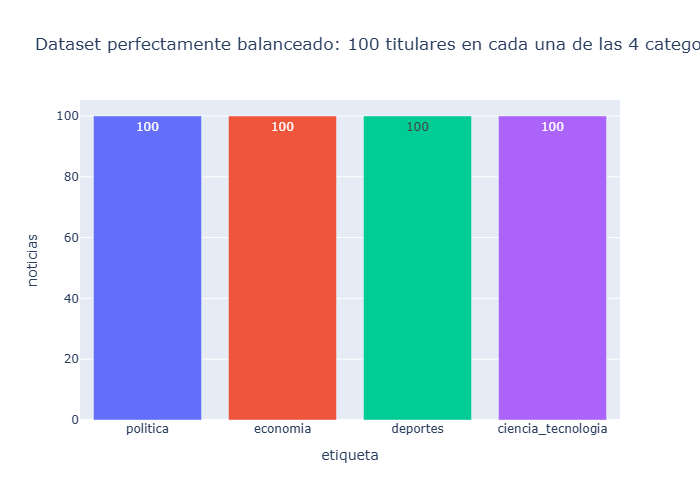

In [10]:
df["largo_titular"] = df.titular.str.len()
dist = df.etiqueta.value_counts().rename_axis("etiqueta").reset_index(name="noticias")
fig1 = px.bar(dist, x="etiqueta", y="noticias", text="noticias", color="etiqueta",
              title=f"Dataset perfectamente balanceado: {dist.noticias.min()} titulares en cada una de las 4 categorías ({len(df)} en total)" if dist.noticias.nunique() == 1
                    else f"Dataset casi balanceado: {dist.noticias.min()}–{dist.noticias.max()} titulares por categoría ({len(df)} en total)")
fig1.update_layout(showlegend=False); fig1.show()

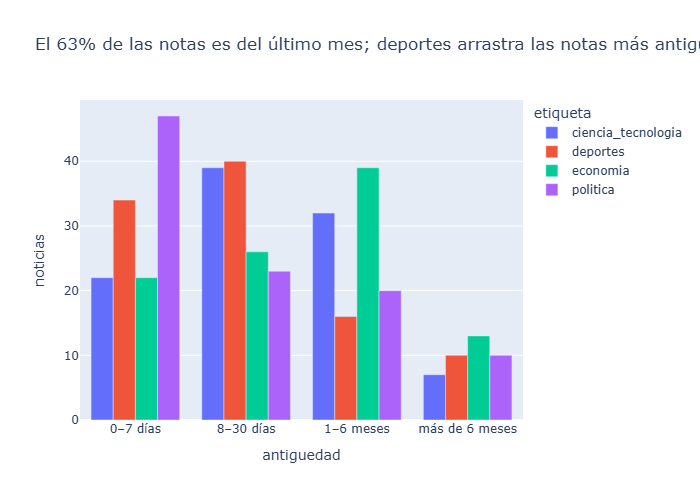

Rango de fechas por categoría:


,min,max
etiqueta,,
ciencia_tecnologia,2026-03-16,2026-10-16
deportes,2024-03-30,2026-10-17
economia,2024-05-05,2026-10-17
politica,2026-02-04,2026-10-17


In [11]:
dias = (pd.Timestamp(FECHA_DESCARGA[:10]) - pd.to_datetime(df.fecha)).dt.days
orden = ["0–7 días", "8–30 días", "1–6 meses", "más de 6 meses"]
df["antiguedad"] = pd.cut(dias, [-1, 7, 30, 182, 10**5], labels=orden)
por_rango = df.groupby(["antiguedad", "etiqueta"], observed=False).size().reset_index(name="noticias")
pct_mes = (dias <= 30).mean()
mas_vieja = df.groupby("etiqueta").fecha.min().idxmin()
fig2 = px.bar(por_rango, x="antiguedad", y="noticias", color="etiqueta", barmode="group", category_orders={"antiguedad": orden},
              title=f"El {pct_mes:.0%} de las notas es del último mes; {mas_vieja} arrastra las notas más antiguas (desde {df.fecha.min()})")
fig2.show()
print("Rango de fechas por categoría:"); display(df.groupby("etiqueta").fecha.agg(["min", "max"]))

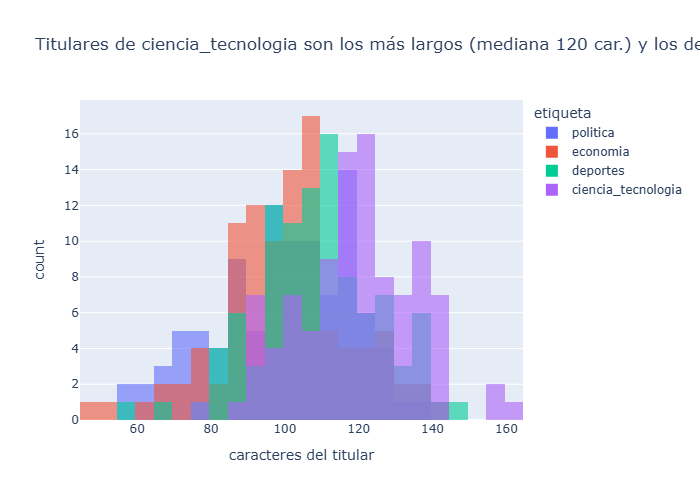

,count,mean,std,min,25%,50%,75%,max
etiqueta,,,,,,,,
ciencia_tecnologia,100.0,119.7,16.1,78.0,109.8,120.0,130.2,162.0
deportes,100.0,108.7,16.9,57.0,98.0,108.0,119.0,148.0
economia,100.0,100.3,17.5,49.0,90.0,101.0,108.0,142.0
politica,100.0,99.4,18.1,58.0,86.8,100.5,115.0,138.0


In [12]:
med = df.groupby("etiqueta").largo_titular.median().sort_values()
fig3 = px.histogram(df, x="largo_titular", color="etiqueta", nbins=30, barmode="overlay", opacity=0.6,
                    labels={"largo_titular": "caracteres del titular"},
                    title=f"Titulares de {med.index[-1]} son los más largos (mediana {med.iloc[-1]:.0f} car.) y los de {med.index[0]} los más cortos ({med.iloc[0]:.0f})")
fig3.show()
df.groupby("etiqueta").largo_titular.describe().round(1)

## 7. Validación: titulares más largos y más cortos

In [13]:
cols = ["titular", "etiqueta", "largo_titular"]
print("5 titulares MÁS LARGOS"); display(df.nlargest(5, "largo_titular")[cols])
print("5 titulares MÁS CORTOS"); display(df.nsmallest(5, "largo_titular")[cols])
print(f"Rango observado: {df.largo_titular.min()}–{df.largo_titular.max()} caracteres, coherente con los extremos del histograma.")

5 titulares MÁS LARGOS


,titular,etiqueta,largo_titular
568,"Esta gigantesca máquina consume tanta electricidad como una ciudad para acelerar partículas al 99,9999991 % de la ve...",ciencia_tecnologia,162
500,"La humanidad roza sus límites: la población mundial alcanzaría los 12.400 millones en 2070, mientras científicos sug...",ciencia_tecnologia,158
563,"Retiraron cabras de una isla cerca de Venezuela para salvar su bosque, pero 15 años después científicos descubrieron...",ciencia_tecnologia,157
377,"Mia Shalit, arquera de Universitario, destaca el nivel de las cremas pese a derrota ante Palmeiras por Copa Libertad...",deportes,148
582,Científicos argentinos descubren una nueva especie de mamífero en el Parque Nacional Traslasierra: vive entre las ro...,ciencia_tecnologia,144


5 titulares MÁS CORTOS


,titular,etiqueta,largo_titular
364,Marco Vinelli jura como nuevo titular del Midagri,economia,49
312,Movistar: Más de 100 comunidades rurales acceden a 4G,economia,53
423,¿Cuándo inicia la Liga Peruana de Vóley Femenina 2026-27?,deportes,57
255,JNE deberá resolver 21 casos de reeleción inconstitucional,politica,58
178,Pugnas políticas entre militantes de Fuerza Popular en Puno,politica,59


Rango observado: 49–162 caracteres, coherente con los extremos del histograma.


## 8. Exportación de `datos/noticias.csv`

In [14]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
final = df[COLUMNAS].reset_index(drop=True)
final.to_csv(DATOS / "noticias.csv", index=False, encoding="utf-8")
print(final.shape)
final.head()

(400, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Keiko Fujimori sobre limpieza del río Piura ante el riesgo de un meganiño: “Más que eso no podemos hacer”,"Además, optó por darle la responsabilidad a la coordinación del gobierno anterior y pidió apoyo a la ciudadanía y al...",La Republica,politica,https://larepublica.pe/politica/2026/10/17/keiko-fujimori-sobre-limpieza-del-rio-piura-ante-el-riesgo-de-un-meganino...,2026-10-17,politica
1,Debate de pedido de facultades sigue entrampado en el Senado por falta de consenso entre oficialismo y oposición,La Comisión de Constitución del Senado todavía mantiene pendiente la discusión del pedido de facultades legislativas...,La Republica,politica,https://larepublica.pe/politica/2026/10/17/debate-de-pedido-de-facultades-sigue-entrampado-en-el-senado-por-falta-de...,2026-10-17,politica
2,"Precio del dólar hoy en Perú, sábado 17 de octubre: consulta el tipo de cambio para compra y venta","Consulta el precio del dólar hoy, sábado 17 de octubre, en Perú y conoce el tipo de cambio para la compra y venta en...",La Republica,economia/precio-del-dolar,https://larepublica.pe/economia/precio-del-dolar/2026/10/17/precio-del-dolar-hoy-en-peru-sabado-17-de-octubre-consul...,2026-10-17,economia
3,Alianza Lima vs Atlético Grau EN VIVO: hora y canal del partido por la fecha 12 del Torneo Clausura de la Liga 1 2026,El enfrentamiento por la jornada 12 del Torneo Clausura entre los equipos de Alianza Lima y Atlético Grau se disputa...,La Republica,deportes,https://larepublica.pe/deportes/2026/10/17/en-vivo-alianza-lima-vs-atletico-grau-a-que-hora-y-donde-ver-partido-de-h...,2026-10-17,deportes
4,"Partidos de hoy, sábado 17 de octubre: horarios y canales para ver fútbol EN VIVO","Conoce EN VIVO la programación de este sábado, horarios y canales de TV de todos los enfrentamientos en el Torneo Cl...",La Republica,deportes,https://larepublica.pe/deportes/2026/10/17/partidos-de-hoy-sabado-17-de-octubre-horarios-y-canales-para-ver-futbol-e...,2026-10-17,deportes


In [15]:
muestra = final.sample(10, random_state=42).url
estados = {u: (descargar(u, reintentos=0) or type("x", (), {"status_code": None})).status_code for u in muestra}
print(Counter(estados.values()))

Counter({200: 10})
